## Visualize ensemble reconstruction results

In [4]:
import jax
jax.config.update('jax_platform_name', 'cpu')
import os 
os.environ['CUDA_VISIBLE_DEVICES'] = ''

import sys 
sys.path.insert(1, '../')

import plotly.graph_objs as go
from plotly.offline import iplot

from jax import numpy as jnp
import numpy as np

from scipy.ndimage import gaussian_filter

import matplotlib.pyplot as plt
import matplotlib as mpl

from tqdm.notebook import tqdm

from functools import partial

In [5]:
pm_seed = 4

i_list = range(128)
# num_its = 
# i_list = list(range(0, 0+num_its)) + list(range(25, 25+num_its)) + list(range(50, 50+num_its)) + list(range(75, 75+num_its))
save_dirs = ['../../exp/vol_c009_3_L_2_Lz_5_proj_gg_shape_sigma_0.25_lam_0.001/%d'%(i) for i in i_list]

# wiener_recon = jnp.load('../../wiener_recon/pm%d_wiener.npy'%pm_seed).transpose((1,2,0))
wiener_recon = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/wiener_jwst_c009.npy').transpose(1, 2, 0)
print(wiener_recon.shape)
ddpm_recon = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/ddpm_jwst_c009.npy')[:, 44:113, 25:94] .transpose(1, 2, 0)
ddpm_samples = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/ddpm_jwst_c009_samples.npy')[:, :, 44:113, 25:94].transpose(0, 2, 3, 1)
density_paths = [save_dir + '/density/density_500.p' for save_dir in save_dirs]
# density_paths_2 = [save_dir + '/density/density_500.p' for save_dir in save_dirs_2]

daps_recon = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/ddpm_jwst_4_nops.npy')[:, 20:89, -69:] .transpose(1, 2, 0)

res = 69

(69, 69, 20)


In [6]:
def mean_subtract(vol, axis=(0,1)): 
    return vol - jnp.mean(vol, axis=axis, keepdims=True)

densities = [mean_subtract(jnp.load(density_path).reshape(res, res, 20)) for density_path in density_paths]
densities_arr = jnp.array(densities)

density_gt = jnp.load(save_dirs[-1] + '/../density_gt.p').reshape(res, res, 20)

pws = jnp.load(save_dirs[0] + '/../pws.npy')
pws_ein = pws.reshape(-1, res, res, 20)

density_gt = mean_subtract(density_gt)
ddpm_recon = mean_subtract(ddpm_recon)
wiener_recon = mean_subtract(wiener_recon)

print(ddpm_recon.shape)
print(wiener_recon.shape)

(69, 69, 20)
(69, 69, 20)


In [7]:
k_gt = jnp.einsum('nhwc,hwc->nhw', pws_ein, density_gt).mean(0)
k_nn = jnp.einsum('nhwc,mhwc->mnhw', pws_ein, densities_arr).mean(1)
k_dm = jnp.einsum('nhwc,hwc->nhw', pws_ein, ddpm_recon).mean(0)
k_daps = jnp.einsum('nhwc,hwc->nhw', pws_ein, daps_recon).mean(0)
k_wiener = jnp.einsum('nhwc,hwc->nhw', pws_ein, wiener_recon).mean(0)

k_dm_samples = jnp.einsum('nhwc,mhwc->mnhw', pws_ein, ddpm_samples).mean(1)

In [8]:
print(k_gt.max(), k_gt.min())

vmin, vmax = k_gt.min(), k_gt.max()

3.39522 -0.047556523


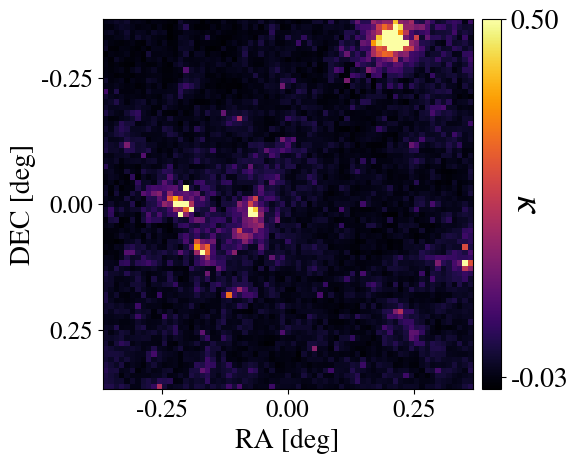

In [9]:
fontsize = 28
vmax=0.5

mpl.rcParams.update({
    "axes.unicode_minus": False,
    "font.family": "serif",
    "font.serif": ["STIXGeneral", "DejaVu Serif", "Times New Roman", "Times"],
    "mathtext.fontset": "stix",   # STIX math
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

deg_per_px = 27.2 / 2560.0
N = k_dm.shape[0]
half_span_deg = (N / 2.0) * deg_per_px

# Flip DEC: larger at the top, smaller at the bottom
extent = (-half_span_deg, half_span_deg,  half_span_deg, -half_span_deg)
ticks = [-0.25, 0.0, 0.25]

# plt.figure(figsize=(, 4))

plt.imshow(k_gt, cmap='inferno', vmin=vmin, vmax=vmax, extent=extent)
plt.xlabel(r'RA [deg]', fontsize=20)
plt.ylabel(r'DEC [deg]', fontsize=20)
plt.xticks(ticks)
plt.yticks(ticks)

fig = plt.gcf()

# Reuse an existing image artist (all share cmap/vmin/vmax)
axes = fig.get_axes()
img0 = None
for ax in axes:
    if ax.images:
        img0 = ax.images[0]
        break

# Single shared colorbar on the right
cbar = fig.colorbar(img0, ax=axes, location='right',
                    fraction=0.05, pad=0.02, ticks=[vmax, -0.03])
cbar.ax.tick_params(labelsize=20)
cbar.set_label(r'$\kappa$', fontsize=fontsize, rotation=270, labelpad=-30, va='center')

# plt.savefig('../jwst_figs/kappa_recon_gt_3.pdf', bbox_inches='tight')
plt.show()

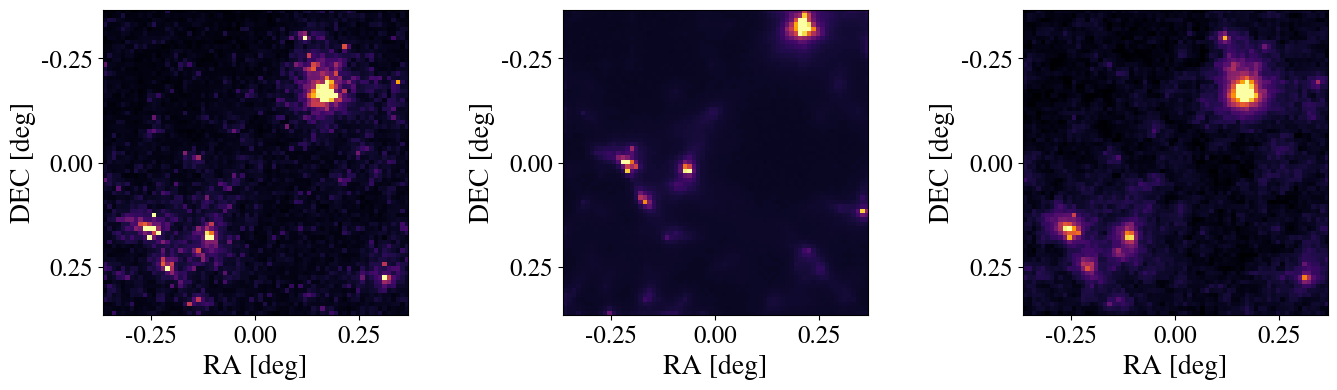

In [10]:
plt.figure(figsize=(14, 4))

ax = plt.subplot(1, 3, 1)
plt.imshow(k_dm, cmap='inferno', vmin=vmin, vmax=vmax, extent=extent)  # origin='upper' by default
ax.set_xlabel(r'RA [deg]', fontsize=20)
ax.set_ylabel(r'DEC [deg]', fontsize=20)
ax.set_xticks(ticks)
ax.set_yticks(ticks)

ax = plt.subplot(1, 3, 2)
plt.imshow(k_nn.mean(0), cmap='inferno', vmin=vmin, vmax=vmax, extent=extent)
ax.set_xlabel(r'RA [deg]', fontsize=20)
ax.set_ylabel(r'DEC [deg]', fontsize=20)
ax.set_xticks(ticks)
ax.set_yticks(ticks)

ax = plt.subplot(1, 3, 3)
plt.imshow(k_wiener, cmap='inferno', vmin=vmin, vmax=vmax, extent=extent)
ax.set_xlabel(r'RA [deg]', fontsize=20)
ax.set_ylabel(r'DEC [deg]', fontsize=20)
ax.set_xticks(ticks)
ax.set_yticks(ticks)

plt.tight_layout()
# plt.savefig('../jwst_figs/kappa_recon_3.pdf', bbox_inches='tight')
plt.show()

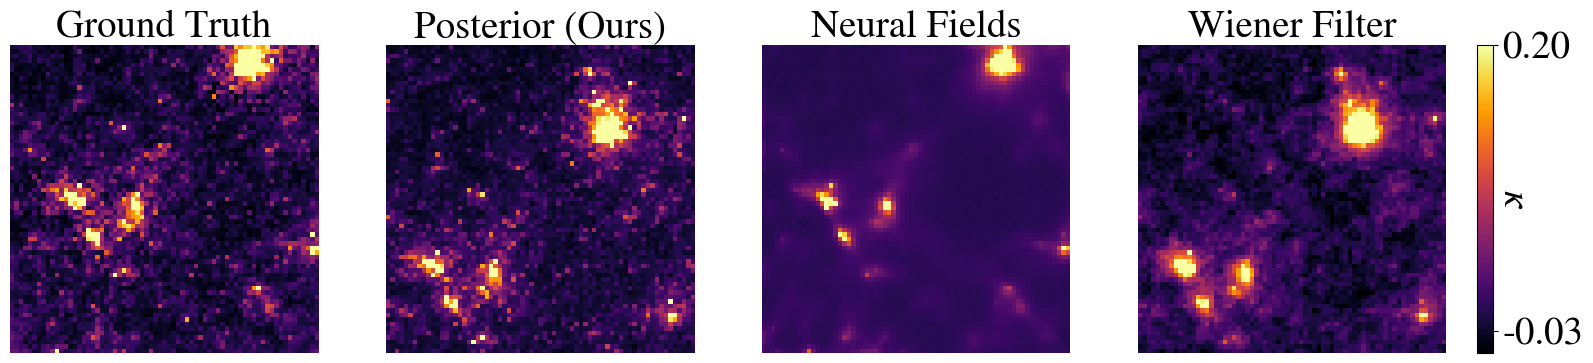

In [11]:
fontsize = 28
vmax=0.2

plt.figure(figsize=(20, 4))

plt.subplot(1, 4, 1)
plt.imshow(k_gt, cmap='inferno', vmin=vmin, vmax=vmax)
plt.title('Ground Truth', fontsize=fontsize)
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(k_dm, cmap='inferno', vmin=vmin, vmax=vmax)
plt.title('Posterior (Ours)', fontsize=fontsize)
plt.axis('off')


plt.subplot(1, 4, 3)
plt.imshow(k_nn.mean(0), cmap='inferno', vmin=vmin, vmax=vmax)
plt.title('Neural Fields', fontsize=fontsize)
plt.axis('off')

plt.subplot(1, 4, 4)
img0 = plt.imshow(k_wiener, cmap='inferno', vmin=vmin, vmax=vmax)
plt.title('Wiener Filter', fontsize=fontsize)
plt.axis('off')

fig = plt.gcf()

# Reuse an existing image artist (all share cmap/vmin/vmax)
axes = fig.get_axes()
img0 = None
for ax in axes:
    if ax.images:
        img0 = ax.images[0]
        break

# Single shared colorbar on the right
cbar = fig.colorbar(img0, ax=axes, location='right',
                    fraction=0.05, pad=0.02, ticks=[0.2, -0.03])
cbar.ax.tick_params(labelsize=fontsize)
cbar.set_label(r'$\kappa$', fontsize=fontsize, rotation=270, labelpad=-50, va='center')

# Leave room for the colorbar
# plt.tight_layout(rect=[0, 0, 0.96, 1])

# plt.savefig('../jwst_figs/kappa_recon.pdf', bbox_inches='tight')
plt.show()

In [12]:
densities_median = jnp.median(densities_arr, axis=0)
densities_mean = jnp.mean(densities_arr, axis=0)
densities_std = jnp.std(densities_arr, axis=0)

print(densities_mean.shape)

(69, 69, 20)


-2.6496022 10


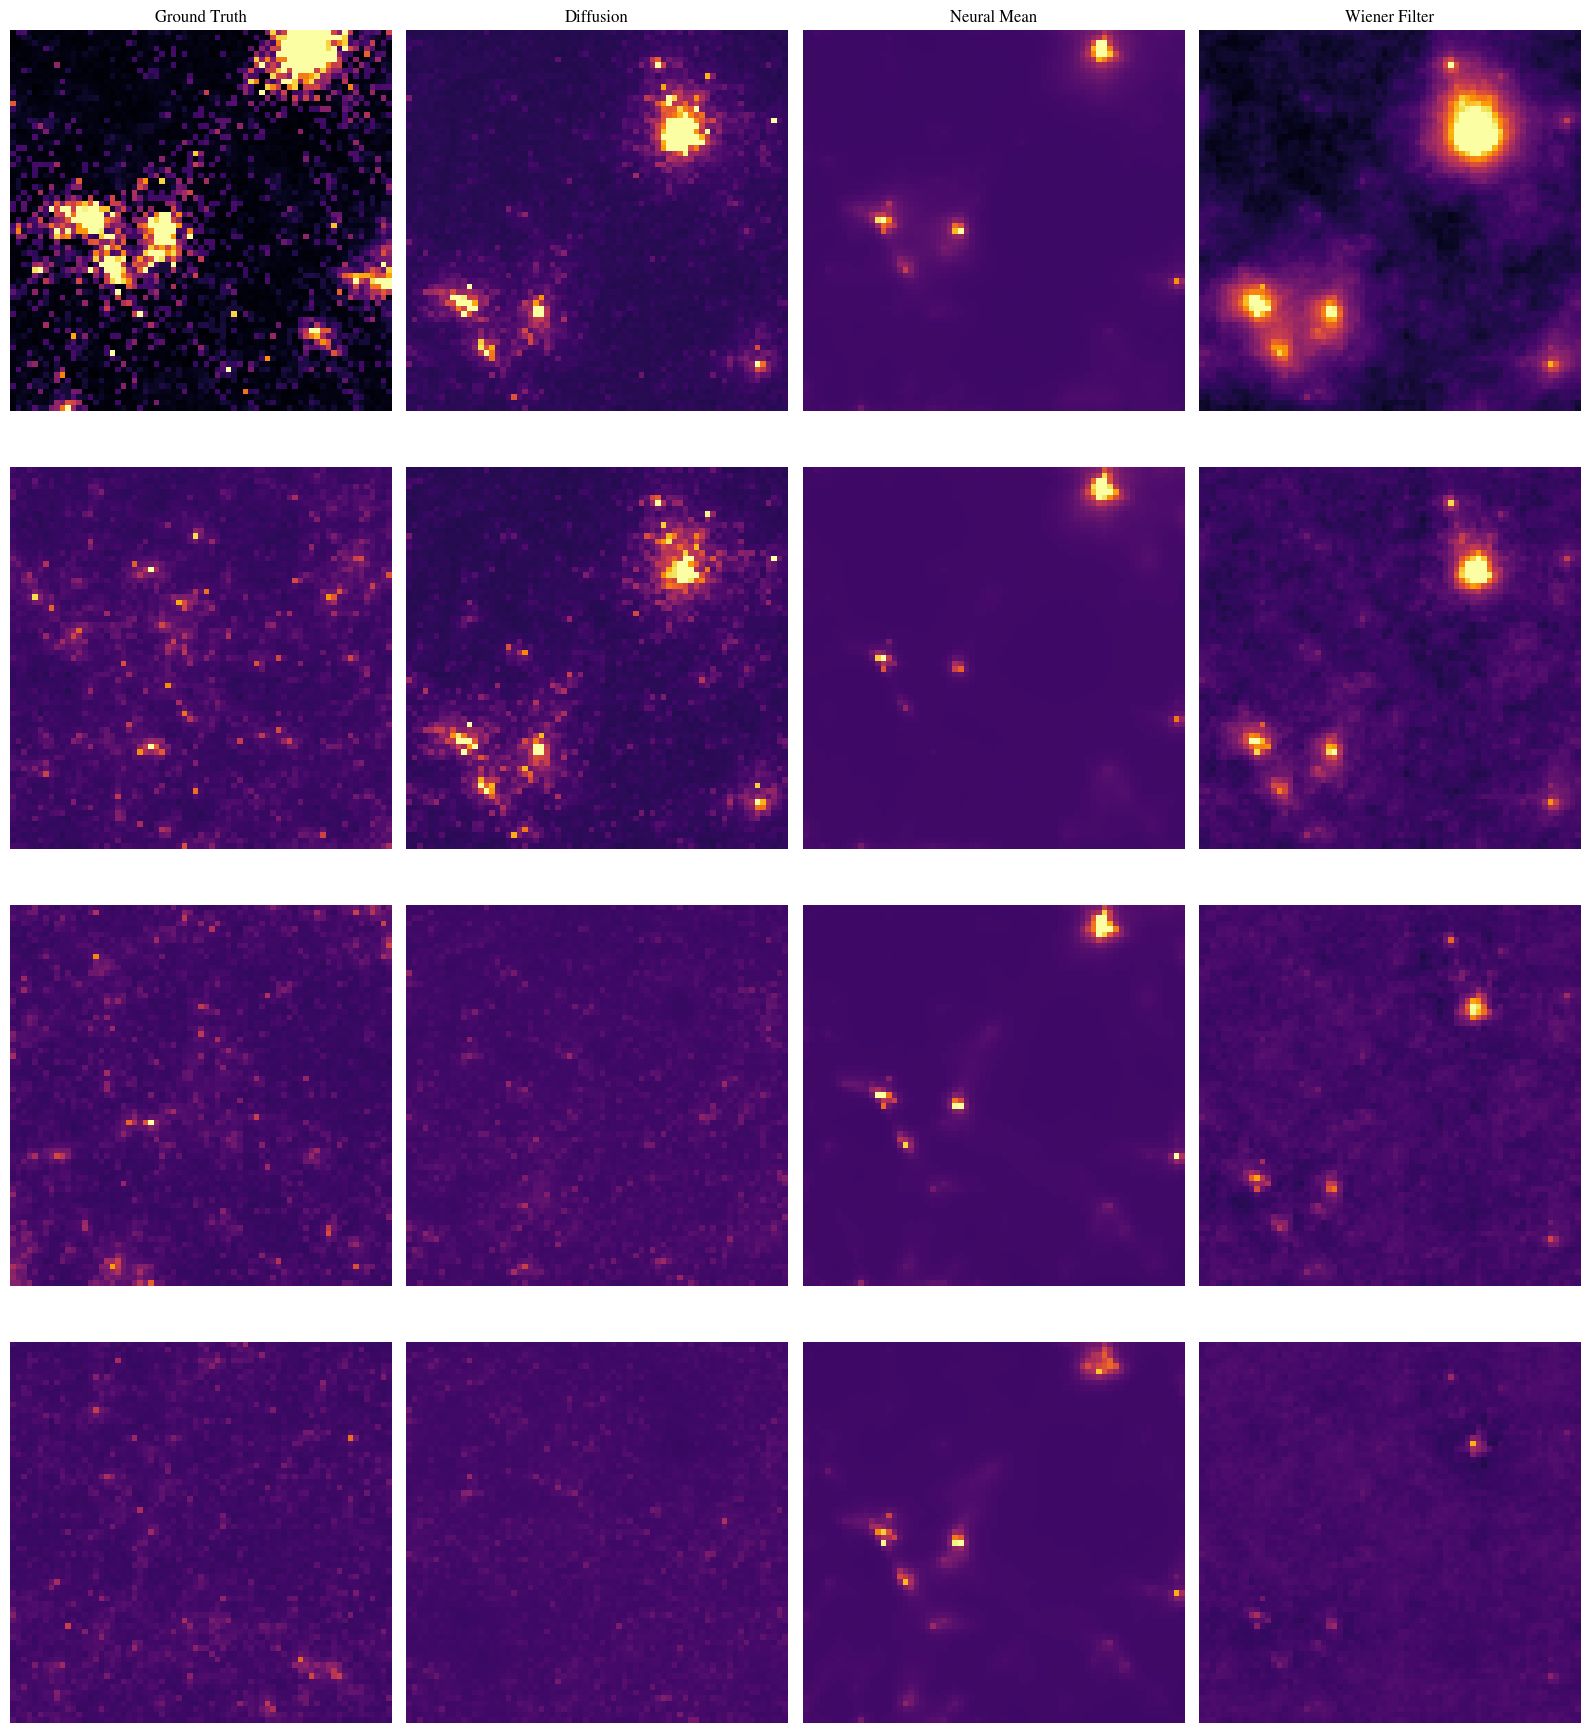

In [13]:
plt.figure(figsize=(16, 18))

slice_avg = lambda vol: vol[..., :12].reshape(res, res, 4, 3).mean(-1)

norm_fn = lambda x: x

vmin = norm_fn(slice_avg(density_gt)).min()
# vmax = norm_fn(slice_avg(density_gt)).max()
vmax = 10

print(vmin, vmax)

for i in range(4): 
    plt.subplot(4, 4, i*4+1)
    plt.imshow(norm_fn(slice_avg(density_gt)[..., i]), cmap='inferno', vmin=vmin, vmax=vmax)
    if i == 0: 
        plt.title('Ground Truth')
    plt.axis('off')

    plt.subplot(4, 4, i*4+2)
    plt.imshow(norm_fn(slice_avg(ddpm_recon)[..., i]), cmap='inferno', vmin=vmin, vmax=vmax)
    if i == 0: 
        plt.title('Diffusion')
    plt.axis('off')

    plt.subplot(4, 4, i*4+3)
    plt.imshow(norm_fn(slice_avg(densities_mean)[..., i]), cmap='inferno', vmin=vmin, vmax=vmax)
    if i == 0: 
        plt.title('Neural Mean')
    plt.axis('off')

    plt.subplot(4, 4, i*4+4)
    plt.imshow(norm_fn(slice_avg(wiener_recon)[..., i]), cmap='inferno', vmin=vmin, vmax=vmax)
    if i == 0: 
        plt.title('Wiener Filter')
    plt.axis('off')

plt.tight_layout()
plt.show()

0.32187192231858686
0.1098176609433519
-0.0764253523656391


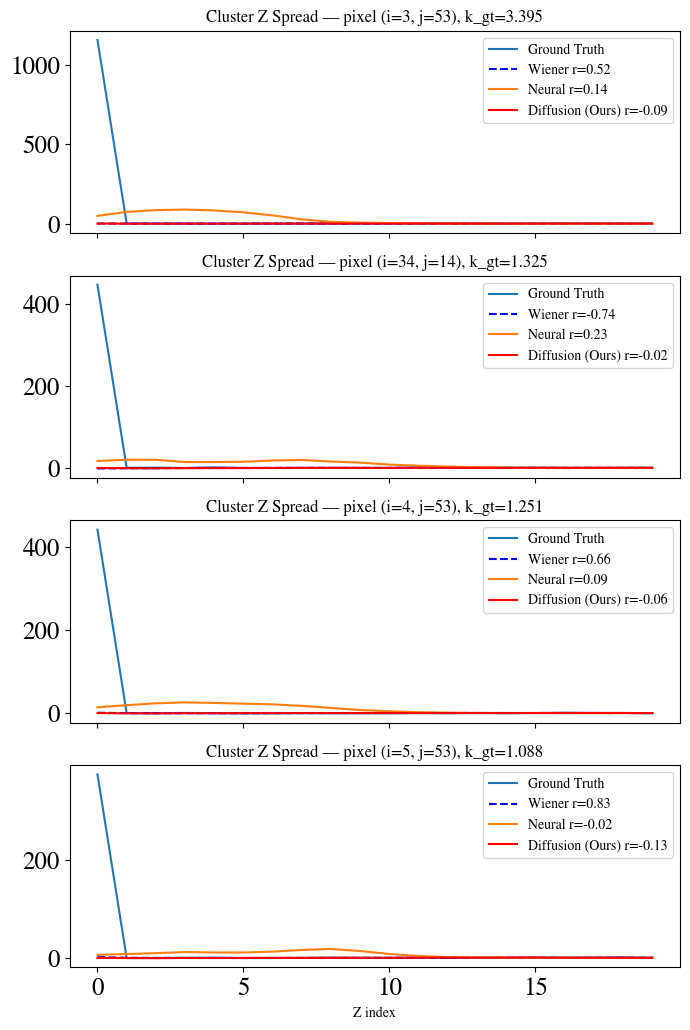

In [14]:
# Get top-5 pixel indices (descending) from k_gt
flat = k_gt.ravel()
topk = 4
# argpartition gets the topk unsorted; then sort those topk descending by value
idx_unsorted = np.argpartition(flat, -topk)[-topk:]
idx_sorted = idx_unsorted[np.argsort(flat[idx_unsorted])[::-1]]  # highest first
coords = np.array(np.unravel_index(idx_sorted, k_gt.shape)).T  # shape (topk, 2)

# Make a figure with one row per top-k pixel
fig, axes = plt.subplots(topk, 1, figsize=(7, 2.6*topk), sharex=True)
if topk == 1:  # handle the degenerate case (axes not iterable)
    axes = [axes]

wiener_ccs = []
neural_ccs = []
ddpm_ccs = []

for ax, (i, j), flat_idx in zip(axes, coords, idx_sorted):

    wiener_cc = np.corrcoef(density_gt[i, j], wiener_recon[i, j])[0, 1]
    neural_cc = np.corrcoef(density_gt[i, j], densities_mean[i, j])[0, 1]
    ddpm_cc = np.corrcoef(density_gt[i, j], ddpm_recon[i, j])[0, 1]

    wiener_ccs.append(wiener_cc)
    neural_ccs.append(neural_cc)
    ddpm_ccs.append(ddpm_cc)

    ax.plot(density_gt[i, j], label=f'Ground Truth')
    ax.plot(wiener_recon[i, j], c='b', linestyle='--', label=f'Wiener r={wiener_cc:.2f}')
    ax.plot(densities_mean[i, j], label=f'Neural r={neural_cc:.2f}')
    ax.plot(ddpm_recon[i, j], c='r', label=f'Diffusion (Ours) r={ddpm_cc:.2f}')

    val = flat[flat_idx]
    ax.set_title(f'Cluster Z Spread — pixel (i={i}, j={j}), k_gt={val:.4g}')
    ax.legend(loc='best')

print(np.mean(wiener_ccs))
print(np.mean(neural_ccs))
print(np.mean(ddpm_ccs))


axes[-1].set_xlabel('Z index')  # or whatever your x-axis is
fig.tight_layout()
plt.show()

In [15]:
def get_mse(gt, recon): 
    gt = mean_subtract(gt)
    recon = mean_subtract(recon)
    return np.mean(np.square(gt - recon))

def get_psnr(gt, recon):
    mse = get_mse(gt, recon)
    max_val = mean_subtract(gt).max()
    psnr = 10 * np.log10(max_val ** 2 / (mse + 1e-10))
    return psnr

def get_pcc(gt, recon):
    gt = mean_subtract(gt).flatten()
    recon = mean_subtract(recon).flatten()
    return np.corrcoef(gt, recon)[0, 1]

def lightcone_avg(metric, gt, recon, return_metrics=False):
    metrics = np.array([metric(gt[..., i], recon[..., i]) for i in range(gt.shape[-1])])
    if return_metrics: 
        return np.mean(metrics, axis=0), metrics
    else: 
        return np.mean(metrics, axis=0)
    
def energy_score(gt, samples, feature=None):
    """
    Energy Score for samples ~ P vs. ground truth gt.
    Optionally pass feature(X) to compute ES in a feature space.
    """
    X = samples.reshape(len(samples), -1)
    y = gt.reshape(1, -1)
    if feature is not None:
        X = feature(X); y = feature(y)
    A = np.linalg.norm(X - y, axis=1).mean()                      # term (A)
    D = np.linalg.norm(X[:, None, :] - X[None, :, :], axis=-1).mean()  # term (B)
    return A - 0.5 * D
    
get_pcc_avg = partial(lightcone_avg, get_pcc)

In [16]:
print(k_gt.shape, k_dm_samples.shape, densities_arr.shape)

(69, 69) (128, 69, 69) (128, 69, 69, 20)


In [17]:
es_k_ddpm = energy_score(k_gt, k_dm_samples)
es_k_neur = energy_score(k_gt, k_nn)

print(es_k_ddpm, es_k_neur)

8.009320318698883 2.2925382256507874


In [18]:
density_gt_blur = gaussian_filter(density_gt, (0, 0, 4.), mode='constant')
ddpm_blur = gaussian_filter(ddpm_recon, (0, 0, 4.), mode='constant')
neur_blur = gaussian_filter(densities_mean, (0, 0, 4.), mode='constant')
wien_blur = gaussian_filter(wiener_recon, (0, 0, 4.), mode='constant')
# for n_planes in range(1, 21):
n_planes = 12
es_ddpm = energy_score(density_gt[..., :n_planes], ddpm_samples[..., :n_planes])
es_neur = energy_score(density_gt[..., :n_planes], densities_arr[..., :n_planes])

print(n_planes, es_ddpm, es_neur)

12 1679.9788818359375 1917.7072143554688


In [19]:
_, pcc_ours = lightcone_avg(get_pcc, density_gt[..., :12], ddpm_recon[..., :12], return_metrics=True)
_, pcc_wien = lightcone_avg(get_pcc, density_gt[..., :12], wiener_recon[..., :12], return_metrics=True)
_, pcc_neur = lightcone_avg(get_pcc, density_gt[..., :12], densities_mean[..., :12], return_metrics=True)

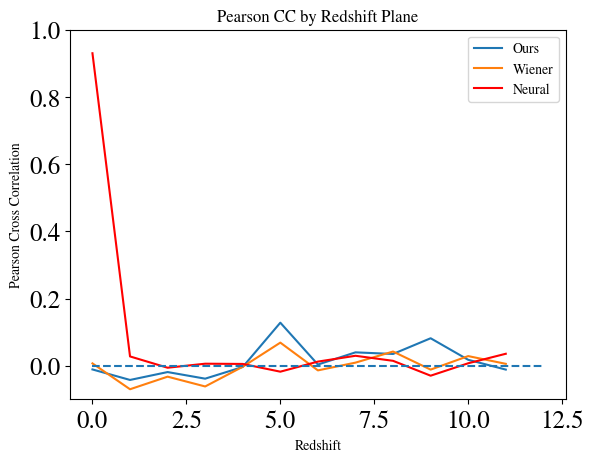

In [20]:
plt.title('Pearson CC by Redshift Plane')

plt.plot(pcc_ours, label='Ours')
plt.plot(pcc_wien, label='Wiener')
plt.plot(pcc_neur, label='Neural', c='r')
plt.hlines(0., 0, 12, linestyles=['dashed'])

plt.ylabel('Pearson Cross Correlation')
plt.xlabel('Redshift')

plt.ylim([-0.1, 1])

plt.legend()
plt.show()

In [21]:
print("==============================================================")
print('PCC 2D: ')
print('Ours: ', get_pcc(k_gt, k_dm))
print('DAPS: ', get_pcc(k_gt, k_daps))
print('Wiener: ', get_pcc(k_gt, k_wiener))
print('Neural: ', get_pcc(k_gt, k_nn.mean(0)))

PCC 2D: 
Ours:  -0.011055980842986394
DAPS:  -0.018320721005369307
Wiener:  -0.016057194076491497
Neural:  0.9540198196203679


In [22]:
print("==============================================================")
print('PCC: ')
print('Ours: ', lightcone_avg(get_pcc, density_gt[..., :12], ddpm_recon[..., :12]))
print('Wiener: ', lightcone_avg(get_pcc, density_gt[..., :12], wiener_recon[..., :12]))
print('Neural: ', lightcone_avg(get_pcc, density_gt[..., :12], densities_mean[..., :12]))

print("==============================================================")
print('PCC Blur: ')
print('Ours: ', lightcone_avg(get_pcc, density_gt_blur[..., :12], ddpm_recon[..., :12]))
print('Wiener: ', lightcone_avg(get_pcc, density_gt_blur[..., :12], wiener_recon[..., :12]))
print('Neural: ', lightcone_avg(get_pcc, density_gt_blur[..., :12], densities_mean[..., :12]))

print("==============================================================")
print('PCC Blur 2: ')
print('Ours: ', lightcone_avg(get_pcc, density_gt_blur[..., :12], ddpm_blur[..., :12]))
print('Wiener: ', lightcone_avg(get_pcc, density_gt_blur[..., :12], wien_blur[..., :12]))
print('Neural: ', lightcone_avg(get_pcc, density_gt_blur[..., :12], neur_blur[..., :12]))

print("==============================================================")
print('MSE: ')
print('Ours: ', lightcone_avg(get_mse, density_gt[..., :12], ddpm_recon[..., :12]))
print('Wiener: ', lightcone_avg(get_mse, density_gt[..., :12], wiener_recon[..., :12]))
print('Neural: ', lightcone_avg(get_mse, density_gt[..., :12], densities_mean[..., :12]))

print("==============================================================")
print('PSNR: ')
print('Ours: ', lightcone_avg(get_psnr, density_gt[..., :12], ddpm_recon[..., :12]))
print('Wiener: ', lightcone_avg(get_psnr, density_gt[..., :12], wiener_recon[..., :12]))
print('Neural: ', lightcone_avg(get_psnr, density_gt[..., :12], densities_mean[..., :12]))


PCC: 
Ours:  0.015007974448047781
Wiener:  -0.0025877587956208035
Neural:  0.08461012868774674
PCC Blur: 
Ours:  -0.005053317330069636
Wiener:  0.00034894222202774074
Neural:  0.7793687580420317
PCC Blur 2: 
Ours:  0.005714377650268128
Wiener:  0.00047918731444905317
Neural:  0.8343578215185022
MSE: 
Ours:  82.72454
Wiener:  78.88007
Neural:  73.02336
PSNR: 
Ours:  23.16923350095749
Wiener:  24.304601947466534
Neural:  24.17271763086319


In [23]:
print("==============================================================")
print('PCC: ')
print('Ours: ', get_pcc(density_gt[..., :12], ddpm_recon[..., :12]))
print('Wiener: ', get_pcc(density_gt[..., :12], wiener_recon[..., :12]))
print('Neural: ', get_pcc(density_gt[..., :12], densities_mean[..., :12]))

print("==============================================================")
print('MSE: ')
print('Ours: ', get_mse(density_gt[..., :12], ddpm_recon[..., :12]))
print('Wiener: ', get_mse(density_gt[..., :12], wiener_recon[..., :12]))
print('Neural: ', get_mse(density_gt[..., :12], densities_mean[..., :12]))

print("==============================================================")
print('PSNR: ')
print('Ours: ', get_psnr(density_gt[..., :12], ddpm_recon[..., :12]))
print('Wiener: ', get_psnr(density_gt[..., :12], wiener_recon[..., :12]))
print('Neural: ', get_psnr(density_gt[..., :12], densities_mean[..., :12]))


PCC: 
Ours:  -0.004226258950963446
Wiener:  0.002833657895062309
Neural:  0.24027775524053988
MSE: 
Ours:  82.72454
Wiener:  78.88007
Neural:  73.02336
PSNR: 
Ours:  42.10421562194824
Wiener:  42.31088638305664
Neural:  42.64594078063965


In [24]:
print(get_pcc(k_gt, k_dm))
print(get_pcc(k_gt, k_wiener))
print(get_pcc(k_gt, k_nn.mean(0)))


print(get_psnr(k_gt, k_dm))
print(get_psnr(k_gt, k_wiener))
print(get_psnr(k_gt, k_nn.mean(0)))

-0.011055980842986394
-0.016057194076491497
0.9540198196203679
28.98789405822754
29.737372398376465
39.13738965988159


In [25]:
def optimal_blur(density_gt, density_recon, sigma_xys, sigma_zs):
    optimal_cc = -100.
    optimal_density_gt = None 
    optimal_sig_xy = None 
    optimal_sig_z = None
    for sig_xy in sigma_xys: 
        for sig_z in sigma_zs: 
            density_gt_blurred = gaussian_filter(density_gt, (sig_xy, sig_xy, sig_z))
            cc = get_pcc_avg(density_gt_blurred, density_recon)
            if cc > optimal_cc: 
                optimal_cc = cc
                optimal_density_gt = density_gt_blurred 
                optimal_sig_xy = sig_xy 
                optimal_sig_z = sig_z 
    return optimal_cc, optimal_density_gt, optimal_sig_xy, optimal_sig_z

def optimal_blur_curve(density_gt, density_recon, sigma_xys, sigma_zs):
    ccs = []
    for sig_xy in sigma_xys: 
        for sig_z in sigma_zs: 
            density_gt_blurred = gaussian_filter(density_gt, (sig_xy, sig_xy, sig_z))
            density_recon_blurred = gaussian_filter(density_recon, (sig_xy, sig_xy, sig_z))
            cc = get_pcc_avg(density_gt_blurred[..., :12], density_recon_blurred[..., :12])
            ccs.append(cc)
    return ccs

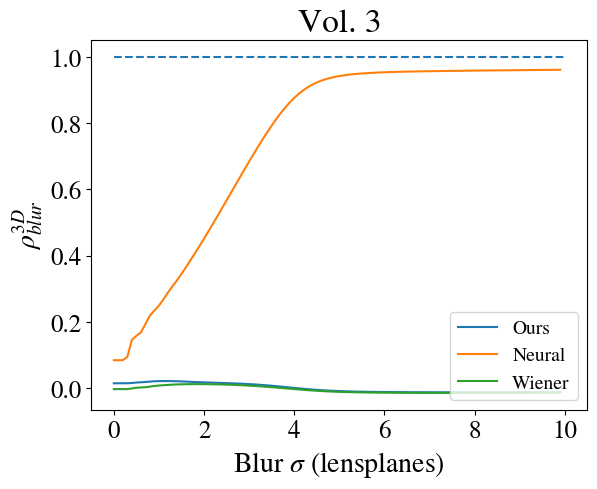

In [26]:
sigma_xys = [0.]
sigma_zs = jnp.linspace(0., 10., num=100, endpoint=False)

ccs_nn = optimal_blur_curve(density_gt, densities_mean, sigma_xys, sigma_zs)
ccs_wn = optimal_blur_curve(density_gt, wiener_recon, sigma_xys, sigma_zs)
ccs_dm = optimal_blur_curve(density_gt, ddpm_recon, sigma_xys, sigma_zs)

plt.hlines(1, 0, 10, linestyles=['dashed'])
plt.plot(sigma_zs, ccs_dm, label='Ours')
plt.plot(sigma_zs, ccs_nn, label='Neural')
plt.plot(sigma_zs, ccs_wn, label='Wiener')

plt.xlabel(r'Blur $\sigma$ (lensplanes)', fontsize=20)
plt.ylabel(r'$\rho_{blur}^{3D}$', fontsize=20)

plt.title('Vol. 3', fontsize=24)
plt.legend(fontsize=14, loc='lower right')
# plt.savefig('../jwst_figs/blur_res_3.svg', bbox_inches='tight')
plt.show()

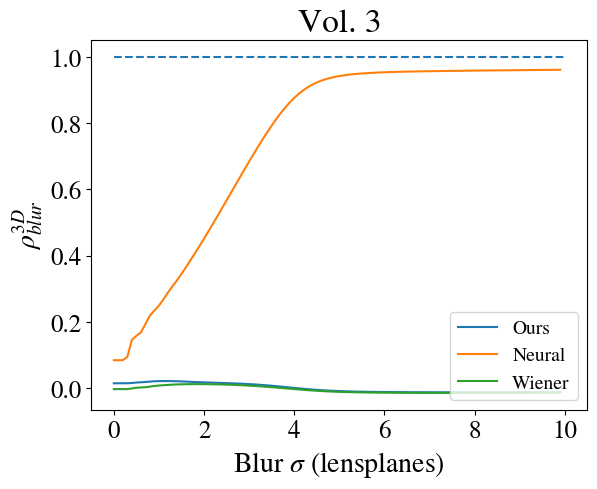

In [27]:
sigma_xys = [0.]
sigma_zs = jnp.linspace(0., 10., num=100, endpoint=False)

ccs_nn = optimal_blur_curve(density_gt, densities_mean, sigma_xys, sigma_zs)
ccs_wn = optimal_blur_curve(density_gt, wiener_recon, sigma_xys, sigma_zs)
ccs_dm = optimal_blur_curve(density_gt, ddpm_recon, sigma_xys, sigma_zs)

plt.hlines(1, 0, 10, linestyles=['dashed'])
plt.plot(sigma_zs, ccs_dm, label='Ours')
plt.plot(sigma_zs, ccs_nn, label='Neural')
plt.plot(sigma_zs, ccs_wn, label='Wiener')

plt.xlabel(r'Blur $\sigma$ (lensplanes)', fontsize=20)
plt.ylabel(r'$\rho_{blur}^{3D}$', fontsize=20)

plt.title('Vol. 3', fontsize=24)
plt.legend(fontsize=14, loc='lower right')
# plt.savefig('../jwst_figs/blur_res_3.svg', bbox_inches='tight')
plt.show()

In [28]:
sigma_xys = [0.]
sigma_zs = jnp.linspace(0., 10., num=100, endpoint=False)

optimal_cc_nn, _, _, optimal_sig_z_nn = optimal_blur(density_gt, densities_mean, sigma_xys, sigma_zs)
optimal_cc_wn, _, _, optimal_sig_z_wn = optimal_blur(density_gt, wiener_recon, sigma_xys, sigma_zs)
optimal_cc_dm, _, _, optimal_sig_z_dm = optimal_blur(density_gt, ddpm_recon, sigma_xys, sigma_zs)

print(optimal_sig_z_nn, optimal_cc_nn)
print(optimal_sig_z_wn, optimal_cc_wn)
print(optimal_sig_z_dm, optimal_cc_dm)

5.9999995 0.6404262658774525
1.6999999 0.018074715845193566
1.4999999 0.021819389292036258
